<h1 style="color:rgb(150,100,10)">Computer Vision</h1>
<h2 style="color:rgb(150,100,10)">Image Processing Basics </h2>

<b>This file is part of the "Computer Vision Course 2026W" UE material.</b>

In [ ]:
%pip install pandas opencv-python matplotlib numpy scikit-image

In [ ]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
import os
import glob
from math import pi
from skimage import feature
import zipfile
import pandas as pd

with zipfile.ZipFile("resources.zip", "r") as zip_ref:
    zip_ref.extractall("/content")

if not os.path.exists("resources") and os.path.exists("resources.zip"):
    with zipfile.ZipFile("resources.zip", "r") as zip_ref:
        zip_ref.extractall(".")

if not os.path.exists("resources"):
    raise TypeError("Please create the resources folder and include all required files.")

print("All necessary packages are successfully installed.")


All necessary packages are successfully installed.


<a name="Blob-Detection"></a>

<h2>Blob Detection and Analysis</h2>

<p>
Building a complete blob detection pipeline.

Starting from an input image, progressively implementing each processing stage, including image preprocessing, thresholding, morphological operations, connected component analysis, and contour detection.

</p>


<b>Preparing the input image for the blob-detection pipeline.</b>

<ul>
<li>Loaded `blob_img_1.jpg` from the `resources` folder using OpenCV.</li>
<li>Converted the image from OpenCV's BGR color format to RGB for correct visualization.</li>
<li>Converted the original image to grayscale for subsequent image-processing steps.</li>
<li>Displayed the RGB and grayscale images side by side.</li>
</ul>


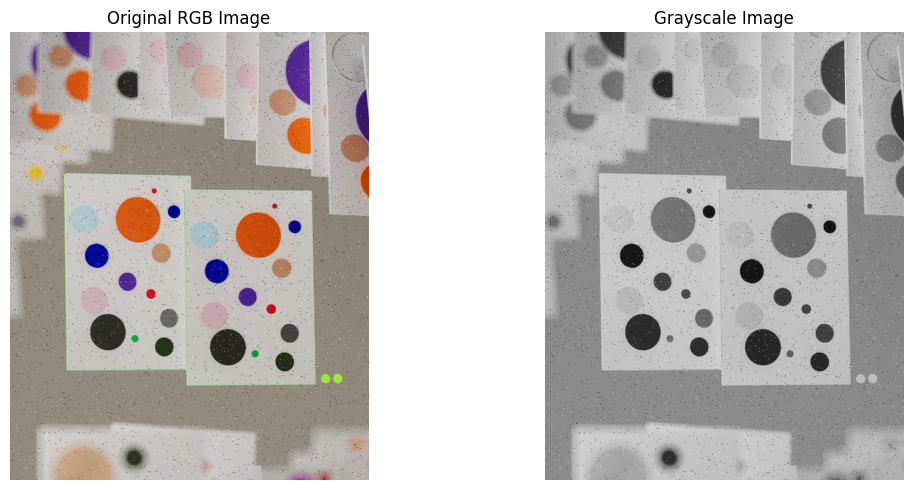

In [ ]:

def load_image(filename):
    # Load image (OpenCV loads images in BGR format)
    image = cv.imread(filename)

    # Convert BGR to RGB
    rgb_image = cv.cvtColor(image, cv.COLOR_BGR2RGB)

    # Convert BGR to Grayscale
    gray_image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

    return rgb_image, gray_image

rgb_image, gray_image = load_image(
    "resources/blob_img_1.jpg"
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_image)
plt.title("Original RGB Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()

<b>A suitable threshold for separating the foreground blobs from the background.</b>

<ul>
<li>Implemented inverse binary thresholding to separate foreground blobs from the darker background.</li>
<li>Evaluated a range of threshold values and visualized the resulting binary images for comparison.</li>
<li>Selected a threshold value based on the visual quality of foreground/background separation.</li>
<li>Stored the selected threshold in `selected_threshold` and generated the corresponding binary image.</li>
</ul>


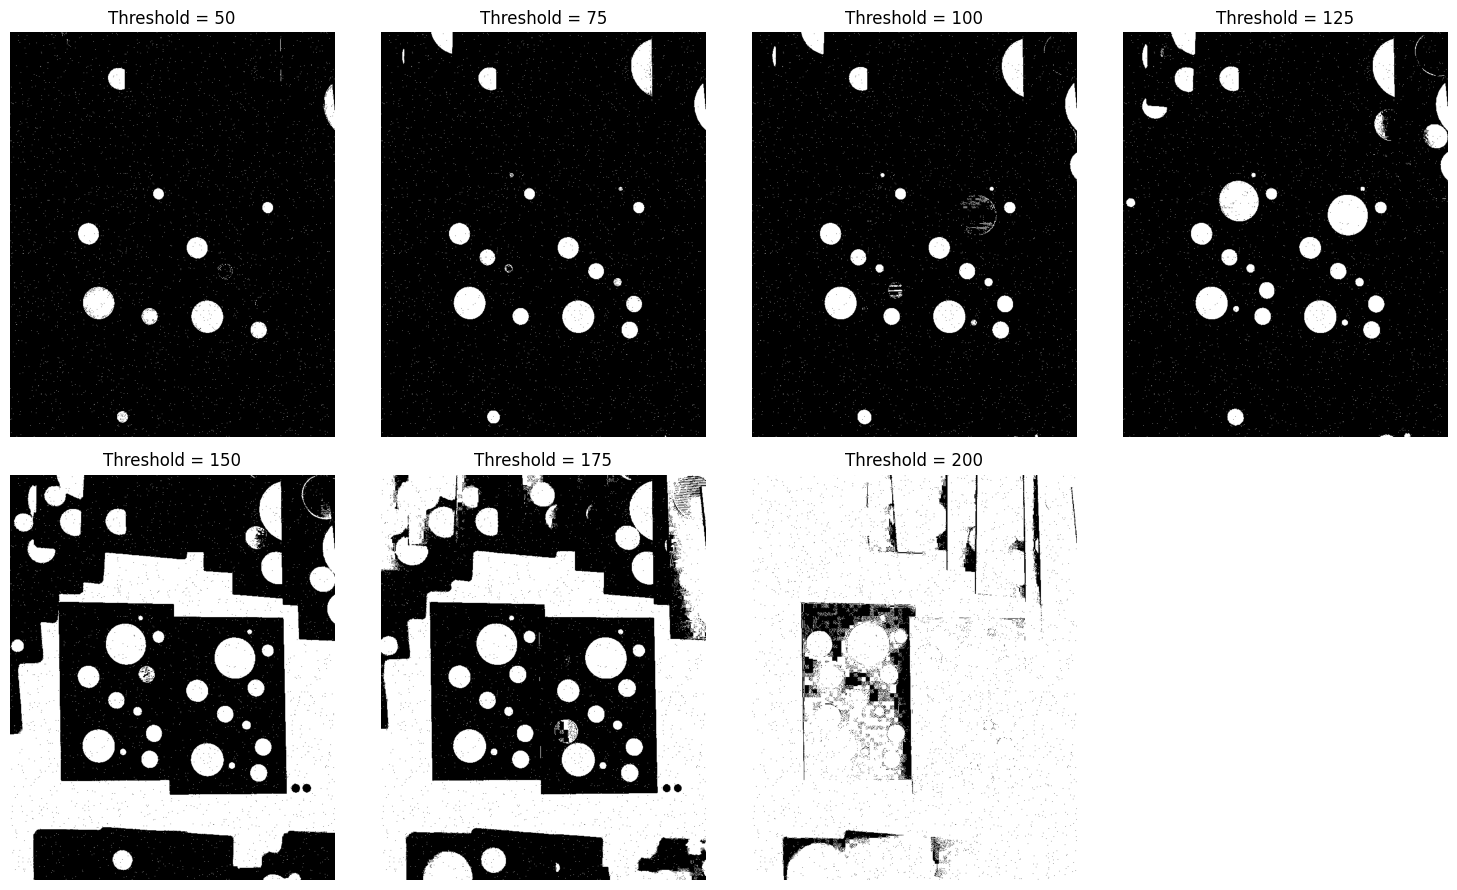

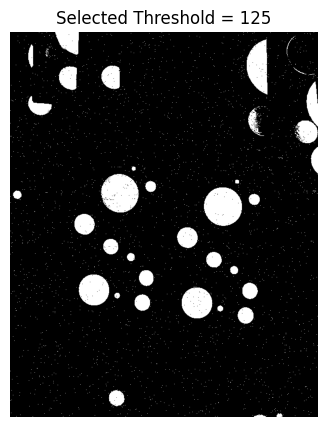

In [ ]:

def threshold_image(gray_image, threshold):

    # Apply inverse binary thresholding
    _, binary_image = cv.threshold(
        gray_image,
        threshold,
        255,
        cv.THRESH_BINARY_INV
    )

    return binary_image

# different threshold values
threshold_values = [50, 75, 100, 125, 150, 175, 200]

plt.figure(figsize=(15, 9))

for i, threshold in enumerate(threshold_values):

    binary_image = threshold_image(gray_image, threshold) # grayscale image from the previous cell

    plt.subplot(2, 4, i + 1)
    plt.imshow(binary_image, cmap="gray")
    plt.title(f"Threshold = {threshold}")
    plt.axis("off")

plt.tight_layout()
plt.show()

selected_threshold = 125

binary_image = threshold_image(
    gray_image,
    selected_threshold
)

plt.figure(figsize=(7, 5))
plt.imshow(binary_image, cmap="gray")
plt.title(f"Selected Threshold = {selected_threshold}")
plt.axis("off")
plt.show()

<b>How Gaussian filtering affects the appearance and detection of image blobs.</b>

<ul>
<li>Applied Gaussian smoothing to the grayscale image before thresholding.</li>

<li>ATested different Gaussian kernel sizes to investigate their effects on noise reduction and blob detail.</li>

<li>Compared the resulting binary images and selected a kernel size that retained the target blob shapes.</li>

<li>Stored the selected kernel size in `selected_gaussian_kernel` and the resulting binary image in `binary_filtered`.</li>
</ul>



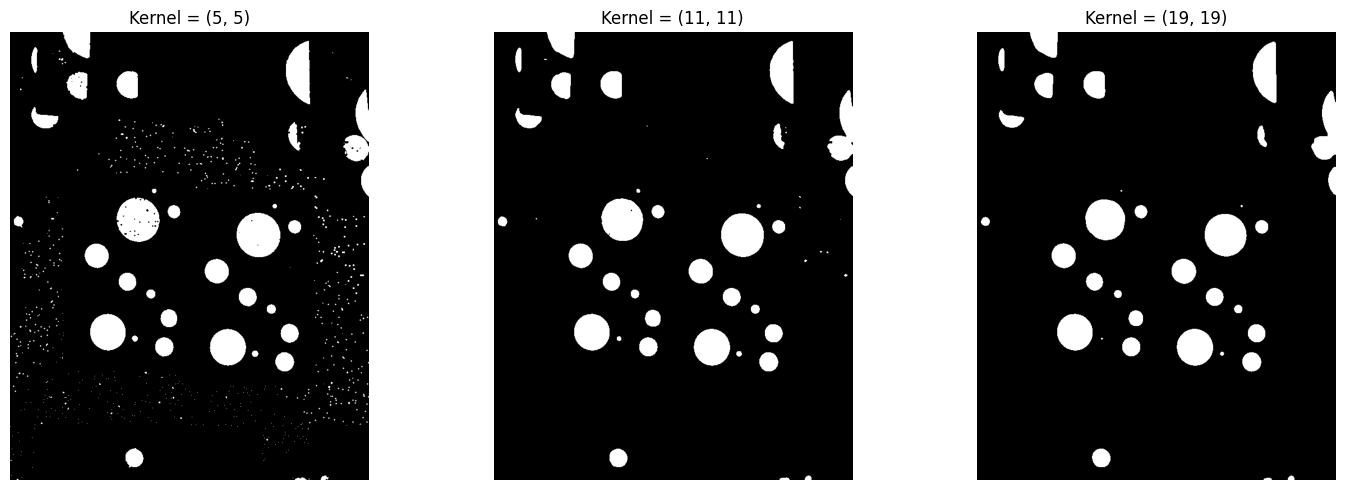

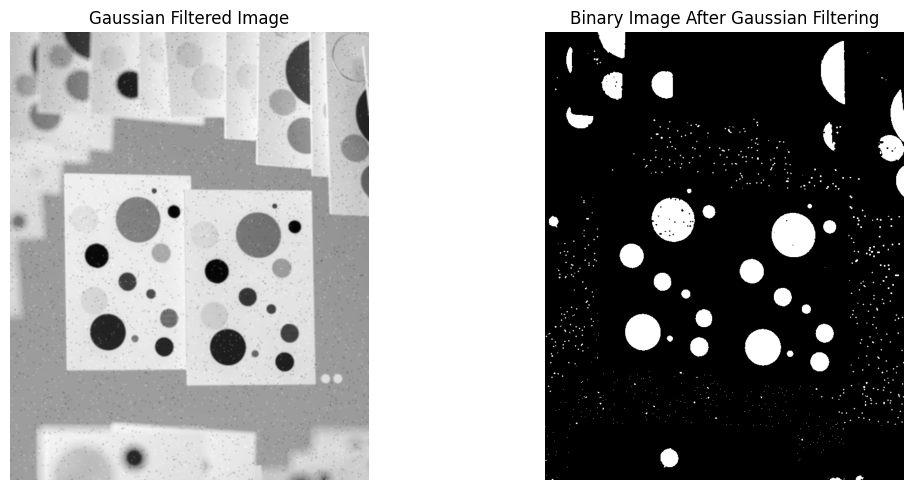

In [ ]:
def apply_gaussian_threshold(gray_image,threshold,kernel_size):

    filtered_image = cv.GaussianBlur(
        gray_image,
        kernel_size,
        0
    )

    # Applying inverse thresholding
    _, binary_image = cv.threshold(
        filtered_image,
        threshold,
        255,
        cv.THRESH_BINARY_INV
    )

    return filtered_image, binary_image

# different Gaussian kernel sizes
kernel_sizes = [(5, 5), (11, 11), (19, 19)]

plt.figure(figsize=(15, 5))

for i, kernel_size in enumerate(kernel_sizes):

    filtered_image, binary_image = apply_gaussian_threshold(
        gray_image,
        selected_threshold,
        kernel_size
    )

    plt.subplot(1, 3, i + 1)
    plt.imshow(binary_image, cmap="gray")
    plt.title(f"Kernel = {kernel_size}")
    plt.axis("off")

plt.tight_layout()
plt.show()


selected_gaussian_kernel = (5, 5)

filtered_image, binary_filtered = apply_gaussian_threshold(
    gray_image,
    selected_threshold,
    selected_gaussian_kernel
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(filtered_image, cmap="gray")
plt.title("Gaussian Filtered Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_filtered, cmap="gray")
plt.title("Binary Image After Gaussian Filtering")
plt.axis("off")

plt.tight_layout()
plt.show()

<b>Refining the detected blobs using morphological operations</b>


<ul>

<li>Created rectangular structuring elements of different sizes.</li>

<li>Applied morphological opening (erosion followed by dilation) to the thresholded image to remove small foreground noise.</li>

<li>Compared the results for different kernel sizes and selected a suitable size that cleaned the image while preserving the target blobs.</li>

<li>Stored the selected kernel size in `selected_morphology_kernel` and the cleaned binary image in `binary_clean`.</li>

<ul>



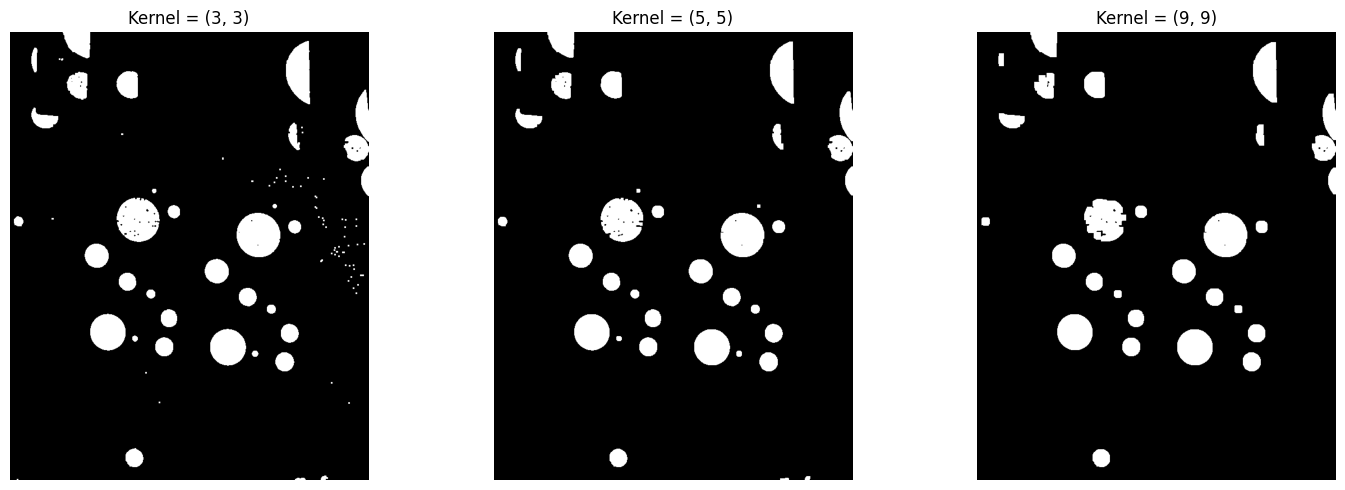

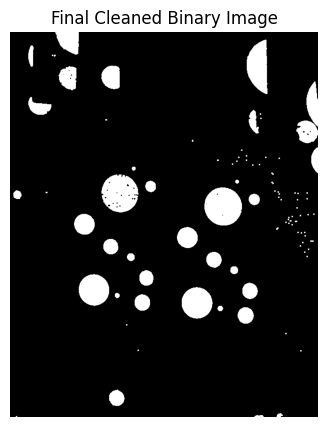

In [ ]:
def apply_morphological_opening(binary_image,kernel_size):

    kernel = cv.getStructuringElement(
        cv.MORPH_RECT,
        kernel_size
    )

    cleaned_image = cv.morphologyEx(
        binary_image,
        cv.MORPH_OPEN,
        kernel
    )

    return cleaned_image

# different structuring element sizes
morphology_sizes = [(3, 3), (5, 5), (9, 9)]

plt.figure(figsize=(15, 5))

for i, kernel_size in enumerate(morphology_sizes):

    cleaned_image = apply_morphological_opening(
        binary_filtered, # binary image from the apply_gaussian_threshold
        kernel_size
    )

    plt.subplot(1, 3, i + 1)
    plt.imshow(cleaned_image, cmap="gray")
    plt.title(f"Kernel = {kernel_size}")
    plt.axis("off")

plt.tight_layout()
plt.show()

selected_morphology_kernel = (3, 3)

binary_clean = apply_morphological_opening(
    binary_filtered,
    selected_morphology_kernel
)

plt.figure(figsize=(7, 5))
plt.imshow(binary_clean, cmap="gray")
plt.title("Final Cleaned Binary Image")
plt.axis("off")
plt.show()

<b>Detecting and analyzing the connected blobs in the binary image.</b>


<ul>

<li>Implemented connected-component detection using OpenCV's `connectedComponentsWithStats()`.</li>

<li>Identified foreground components while excluding the background label.</li>

<li>Extracted component statistics, including area, bounding-box width and height, centroid coordinates, and aspect ratio.</li>

<li>Displayed the label image and compiled the measurements into a table.</li>

<li>Identified the smallest component, largest component, and component with the largest bounding-box aspect ratio.</li>

</ul>




Number of detected blobs: 92


,Label,Area,Width,Height,Centroid X,Centroid Y,Aspect Ratio
0,1,1695,49,47,122.22,18.86,1.04
1,2,3559,43,113,515.76,71.02,0.38
2,3,365,11,44,43.26,49.10,0.25
3,4,9,3,3,88.00,48.00,1.00
4,5,14,4,4,92.50,48.50,1.00
...,...,...,...,...,...,...,...
87,88,9,3,3,604.00,662.00,1.00
88,89,834,32,34,221.21,760.14,0.94
89,90,75,13,8,559.76,795.88,1.62
90,91,64,19,4,517.33,797.73,4.75



Smallest Blob:
Label            92.0
Area              6.0
Width             3.0
Height            2.0
Centroid X       13.0
Centroid Y      798.5
Aspect Ratio      1.5
Name: 91, dtype: float64

Largest Blob:
Label             34.00
Area            4872.00
Width             78.00
Height            79.00
Centroid X       442.48
Centroid Y       362.14
Aspect Ratio       0.99
Name: 33, dtype: float64

Largest Aspect Ratio Blob:
Label            91.00
Area             64.00
Width            19.00
Height            4.00
Centroid X      517.33
Centroid Y      797.73
Aspect Ratio      4.75
Name: 90, dtype: float64


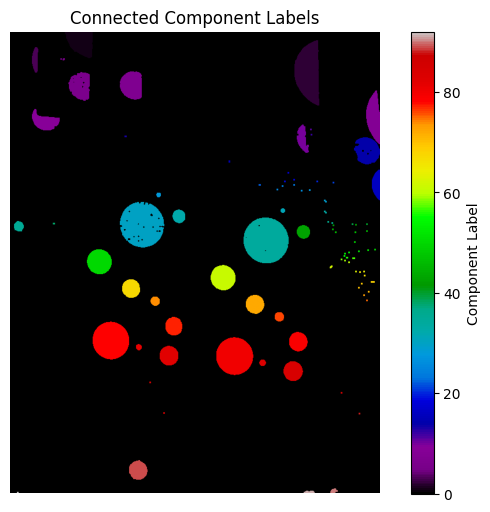

In [ ]:
def detect_blobs(binary_image):

    num_labels, labels, stats, centroids = (
        cv.connectedComponentsWithStats(
            binary_image,
            connectivity=8
        )
    )

    return num_labels, labels, stats, centroids

num_labels, labels, stats, centroids = detect_blobs(
    binary_clean # binary image from the apply_morphological_opening function
)

blob_data = []

for label in range(1, num_labels):

    area = stats[label, cv.CC_STAT_AREA]
    x = stats[label, cv.CC_STAT_LEFT]
    y = stats[label, cv.CC_STAT_TOP]
    width = stats[label, cv.CC_STAT_WIDTH]
    height = stats[label, cv.CC_STAT_HEIGHT]

    centroid_x, centroid_y = centroids[label]

    aspect_ratio = width / height

    blob_data.append({
        "Label": label,
        "Area": area,
        "Width": width,
        "Height": height,
        "Centroid X": round(centroid_x, 2),
        "Centroid Y": round(centroid_y, 2),
        "Aspect Ratio": round(aspect_ratio, 2)
    })


blob_df = pd.DataFrame(blob_data)

print("Number of detected blobs:", num_labels - 1)
display(blob_df) # display from pandas to show the DataFrame in a tabular format


# smallest, largest and largest aspect ratio blobs
if len(blob_df) > 0:

    smallest_blob = blob_df.loc[blob_df["Area"].idxmin()] # dataframe.loc Access a group of rows and columns by label(s) or a boolean array.
    largest_blob = blob_df.loc[blob_df["Area"].idxmax()]
    largest_aspect_blob = blob_df.loc[
        blob_df["Aspect Ratio"].idxmax()
    ]

    print("\nSmallest Blob:")
    print(smallest_blob)

    print("\nLargest Blob:")
    print(largest_blob)

    print("\nLargest Aspect Ratio Blob:")
    print(largest_aspect_blob)


plt.figure(figsize=(8, 6))
plt.imshow(labels, cmap="nipy_spectral")
plt.title("Connected Component Labels")
plt.colorbar(label="Component Label")
plt.axis("off")
plt.show()

<b>Visualizing the detected blobs and their geometric properties.</b>



<ul>

<li>Annotated the original RGB image with bounding boxes, centroids, labels, and blob areas.</li>

<li>Highlighted the smallest blob, largest blob, and blob with the largest aspect ratio using distinct colors.</li>

<li>Used a consistent color for the remaining blobs and displayed the final annotated image.</li>

<ul>





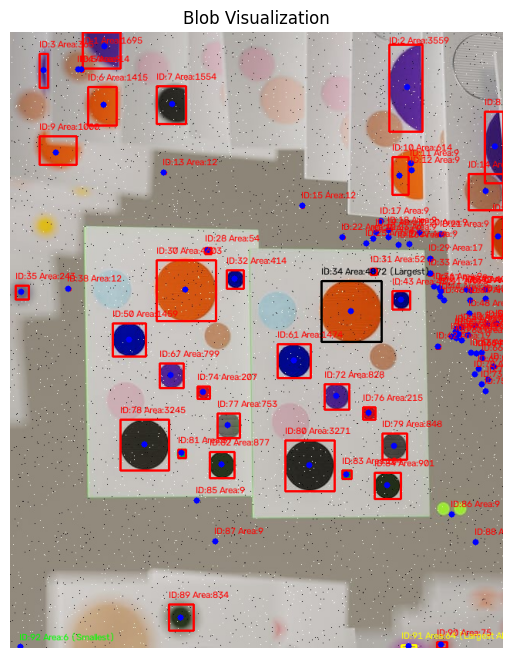

In [ ]:
def visualize_blobs(rgb_image,num_labels,stats,centroids,smallest_label,largest_label,largest_aspect_label):
    annotated_image = rgb_image.copy()

    for label in range(1, num_labels):

        x = stats[label, cv.CC_STAT_LEFT]
        y = stats[label, cv.CC_STAT_TOP]
        width = stats[label, cv.CC_STAT_WIDTH]
        height = stats[label, cv.CC_STAT_HEIGHT]
        area = stats[label, cv.CC_STAT_AREA]

        cx, cy = centroids[label]

        is_smallest = label == smallest_label
        is_largest = label == largest_label
        is_largest_aspect = label == largest_aspect_label

        if is_largest:
            color = (0, 0, 0)          # Black
        elif is_smallest:
            color = (0, 255, 0)        # Green
        elif is_largest_aspect:
            color = (255, 255, 0)      # Yellow
        else:
            color = (255, 0, 0)        # Red

        cv.rectangle(
            annotated_image,
            (x, y),
            (x + width, y + height),
            color,
            2
        )

        cv.circle(
            annotated_image,
            (int(cx), int(cy)),
            4,
            (0, 0, 255),
            -1
        )

        properties = []

        if is_smallest:
            properties.append("Smallest")

        if is_largest:
            properties.append("Largest")

        if is_largest_aspect:
            properties.append("Largest AR")

        text = f"ID:{label} Area:{area}"

        if properties:
            text += " (" + ", ".join(properties) + ")"

        # Draw label and area
        cv.putText(
            annotated_image,
            text,
            (x, max(y - 8, 15)),
            cv.FONT_HERSHEY_SIMPLEX,
            0.4,
            color,
            1
        )


    return annotated_image

if len(blob_df) > 0:

    smallest_label = int(smallest_blob["Label"])
    largest_label = int(largest_blob["Label"])
    largest_aspect_label = int(largest_aspect_blob["Label"])

    annotated_image = visualize_blobs(
        rgb_image,
        num_labels,
        stats,
        centroids,
        smallest_label,
        largest_label,
        largest_aspect_label
    )

    plt.figure(figsize=(12, 8))
    plt.imshow(annotated_image)
    plt.title("Blob Visualization")
    plt.axis("off")
    plt.show()

<b>Detecting object boundaries using contour detection.</b>


<ul>

<li>Detected external contours in the cleaned binary image.</li>

<li>Drew the contours on a copy of the original RGB image.</li>

<li>Calculated contour area and perimeter.</li>

<li>Detect all external contours.</li>

<li>Used image moments to estimate contour centroids and annotated the image with contour IDs, areas, and perimeters.</li>

<li>Displayed the contour visualization.</li>

</ul>




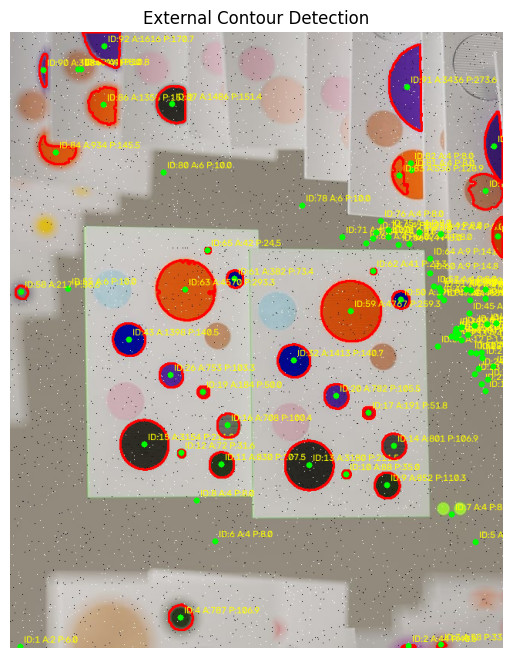

In [ ]:
def detect_contours(binary_image,rgb_image):

    # external contours
    contours, hierarchy = cv.findContours(
        binary_image,
        cv.RETR_EXTERNAL,
        cv.CHAIN_APPROX_SIMPLE
    )

    contour_image = rgb_image.copy()
    for i, contour in enumerate(contours):

        area = cv.contourArea(contour)

        perimeter = cv.arcLength(contour, True)

        M = cv.moments(contour)

        if M["m00"] != 0:

            cx = int(M["m10"] / M["m00"])
            cy = int(M["m01"] / M["m00"])

            cv.drawContours(
                contour_image,
                [contour],
                -1,
                (255, 0, 0),
                2
            )

            cv.circle(
                contour_image,
                (cx, cy),
                4,
                (0, 255, 0),
                -1
            )

            # contour information
            text = f"ID:{i+1} A:{area:.0f} P:{perimeter:.1f}"

            cv.putText(
                contour_image,
                text,
                (cx + 5, cy - 5),
                cv.FONT_HERSHEY_SIMPLEX,
                0.4,
                (255, 255, 0),
                1
            )

    return contour_image

contour_image = detect_contours(
    binary_clean,
    rgb_image
)

plt.figure(figsize=(12, 8))
plt.imshow(contour_image)
plt.title("External Contour Detection")
plt.axis("off")
plt.show()

<b>Remove noisy blobs using geometric properties.</b>



<ul>

<li>Implemented a filtering function based on connected-component geometric statistics.</li>

<li>Retained blobs that satisfy all three conditions: area greater than 50 pixels, width greater than 10 pixels, and height greater than 10 pixels.</li>

<li>Drew bounding boxes and labels for the retained blobs.</li>

<li>Reported the number of detected blobs before and after filtering and displayed the filtered visualization.</li>

<ul>




Blobs before filtering: 92
Blobs after filtering: 29


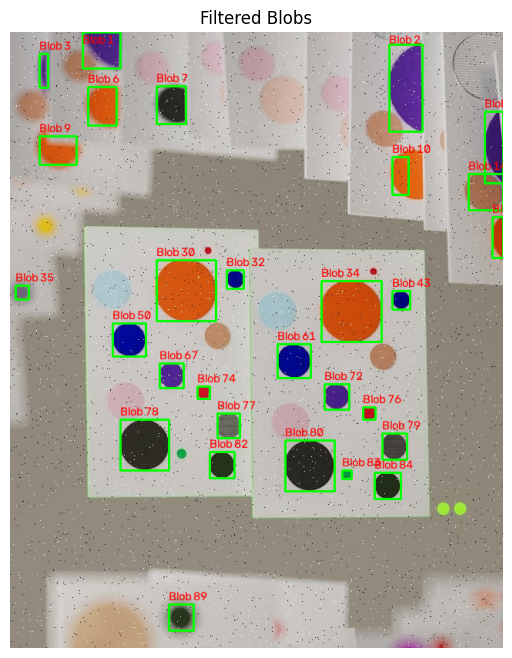

In [ ]:
def filter_blobs(rgb_image,stats,num_labels,min_area,min_width,min_height):


    filtered_image = rgb_image.copy()

    remaining_blobs = 0

    for label in range(1, num_labels):

        x = stats[label, cv.CC_STAT_LEFT]
        y = stats[label, cv.CC_STAT_TOP]

        width = stats[label, cv.CC_STAT_WIDTH]
        height = stats[label, cv.CC_STAT_HEIGHT]

        area = stats[label, cv.CC_STAT_AREA]

        # checking all filtering conditions
        if (
            area > min_area
            and width > min_width
            and height > min_height
        ):

            remaining_blobs += 1

            cv.rectangle(
                filtered_image,
                (x, y),
                (x + width, y + height),
                (0, 255, 0),
                2
            )

            cv.putText(
                filtered_image,
                f"Blob {label}",
                (x, max(y - 5, 15)),
                cv.FONT_HERSHEY_SIMPLEX,
                0.5,
                (255, 0, 0),
                1
            )

    return filtered_image, remaining_blobs

blobs_before = num_labels - 1

filtered_image, remaining_blobs = filter_blobs(
    rgb_image,
    stats,
    num_labels,
    min_area=50,
    min_width=10,
    min_height=10
)

print("Blobs before filtering:", blobs_before)
print("Blobs after filtering:", remaining_blobs)

plt.figure(figsize=(12, 8))
plt.imshow(filtered_image)
plt.title("Filtered Blobs")
plt.axis("off")
plt.show()